In [ ]:
'''Implement Random Search hyperparameter tuning to efficiently explore a broad search space, 
leveraging probabilistic sampling to optimize model parameters under computational constraints.'''

In [1]:
# import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings

from scipy.stats import randint

from sklearn.model_selection import train_test_split, RandomizedSearchCV, KFold
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline

from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [2]:
# load pharmacy sales dataset

df = pd.read_csv("global_pharmacy_sales_data.csv")

print("dataset shape:", df.shape)

display(df.head())

print("\nmissing values:")
print(df.isnull().sum())

dataset shape: (177990, 14)


,date,year,month,day,region,country,category,medicine,age_group,units_sold,unit_price,stock_level,expiry_days_remaining,covid_flag
0,2025-10-12,2025,10,12,Middle East,UAE,Chronic,Amlodipine,0-12,328,45.38,4774,466,0
1,2020-09-15,2020,9,15,South Asia,India,Chronic,Amlodipine,26-45,371,75.49,4584,181,1
2,2020-02-26,2020,2,26,Middle East,UAE,Vitamin,Vitamin C,0-12,948,22.51,3934,556,1
3,2025-11-09,2025,11,9,South Asia,Sri Lanka,Chronic,Amlodipine,0-12,275,63.29,4544,330,0
4,2022-04-04,2022,4,4,South America,Argentina,Chronic,Amlodipine,26-45,563,44.28,4284,590,0



missing values:
date                     0
year                     0
month                    0
day                      0
region                   0
country                  0
category                 0
medicine                 0
age_group                0
units_sold               0
unit_price               0
stock_level              0
expiry_days_remaining    0
covid_flag               0
dtype: int64


In [3]:
#Data preprocessing 
# clean dataset and separate features and target

df = df.drop_duplicates()

df = df.drop(columns=["date"], errors="ignore")

df = df.dropna(subset=["units_sold"])

X = df.drop(columns=["units_sold"])

y = df["units_sold"]

# identify numerical and categorical features

numeric_features = X.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("numerical features:", numeric_features)
print("categorical features:", categorical_features)

print("target variable: units_sold")

numerical features: ['year', 'month', 'day', 'unit_price', 'stock_level', 'expiry_days_remaining', 'covid_flag']
categorical features: ['region', 'country', 'category', 'medicine', 'age_group']
target variable: units_sold


In [4]:
# split data into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("training records:", len(X_train))
print("testing records:", len(X_test))

training records: 140288
testing records: 35072


In [5]:
# apply scaling and categorical encoding

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

print("feature preprocessing completed")

feature preprocessing completed


In [6]:
# define regression algorithms for randomized optimization

models = {
    "Decision Tree": DecisionTreeRegressor(random_state=42),

    "Random Forest": RandomForestRegressor(
        random_state=42,
        n_jobs=1
    ),

    "Extra Trees": ExtraTreesRegressor(
        random_state=42,
        n_jobs=1
    )
}

print("selected algorithms:")

for name in models:
    print(name)

selected algorithms:
Decision Tree
Random Forest
Extra Trees


In [7]:
# define probability-based parameter distributions

parameter_distributions = {

    "Decision Tree": {
        "model__max_depth": [None, 5, 10, 15, 20, 30],
        "model__min_samples_split": randint(2, 30),
        "model__min_samples_leaf": randint(1, 15),
        "model__max_features": [None, "sqrt", 0.8]
    },

    "Random Forest": {
        "model__n_estimators": randint(50, 151),
        "model__max_depth": [None, 10, 15, 20, 25],
        "model__min_samples_split": randint(2, 20),
        "model__min_samples_leaf": randint(1, 10),
        "model__max_features": ["sqrt", 0.8, 1.0]
    },

    "Extra Trees": {
        "model__n_estimators": randint(50, 151),
        "model__max_depth": [None, 10, 15, 20, 25],
        "model__min_samples_split": randint(2, 20),
        "model__min_samples_leaf": randint(1, 10),
        "model__max_features": ["sqrt", 0.8, 1.0]
    }
}

print("randomized parameter search spaces defined")

randomized parameter search spaces defined


In [8]:
# configure shuffled cross-validation

cv_strategy = KFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

print("cross-validation folds:", cv_strategy.n_splits)

cross-validation folds: 3


In [9]:
# select a representative sample to reduce computational requirements

tuning_size = min(10000, len(X_train))

X_tuning = X_train.sample(
    n=tuning_size,
    random_state=42
)

y_tuning = y_train.loc[X_tuning.index]

print("tuning sample records:", len(X_tuning))

tuning sample records: 10000


In [10]:
# perform randomized search using probabilistic parameter sampling

random_results = []

best_estimators = {}

random_search_objects = {}

for name, model in models.items():

    print("\noptimizing:", name)

    # create preprocessing and model pipeline

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    # configure randomized search

    random_search = RandomizedSearchCV(
        estimator=pipeline,
        param_distributions=parameter_distributions[name],
        n_iter=12,
        scoring="neg_root_mean_squared_error",
        cv=cv_strategy,
        n_jobs=2,
        random_state=42,
        verbose=1,
        refit=True,
        pre_dispatch="2*n_jobs"
    )

    # execute randomized parameter sampling

    random_search.fit(X_tuning, y_tuning)

    # save best optimized model

    best_estimators[name] = random_search.best_estimator_

    random_search_objects[name] = random_search

    # store optimization results

    random_results.append({
        "Model": name,
        "Best CV RMSE": -random_search.best_score_,
        "Best Parameters": random_search.best_params_,
        "Iterations": random_search.n_iter
    })

    print("best parameters:", random_search.best_params_)

    print(
        "best cv rmse:",
        round(-random_search.best_score_, 4)
    )

print("\nall randomized searches completed")


optimizing: Decision Tree
Fitting 3 folds for each of 12 candidates, totalling 36 fits
best parameters: {'model__max_depth': 10, 'model__max_features': 0.8, 'model__min_samples_leaf': 5, 'model__min_samples_split': 10}
best cv rmse: 95.7027

optimizing: Random Forest
Fitting 3 folds for each of 12 candidates, totalling 36 fits
best parameters: {'model__max_depth': 20, 'model__max_features': 1.0, 'model__min_samples_leaf': 3, 'model__min_samples_split': 13, 'model__n_estimators': 104}
best cv rmse: 87.5233

optimizing: Extra Trees
Fitting 3 folds for each of 12 candidates, totalling 36 fits
best parameters: {'model__max_depth': 20, 'model__max_features': 1.0, 'model__min_samples_leaf': 3, 'model__min_samples_split': 13, 'model__n_estimators': 104}
best cv rmse: 85.6443

all randomized searches completed


In [11]:
# compare randomized search performance

results_df = pd.DataFrame(random_results)

results_df = results_df.sort_values(
    by="Best CV RMSE",
    ascending=True
).reset_index(drop=True)

display(results_df)

,Model,Best CV RMSE,Best Parameters,Iterations
0,Extra Trees,85.644315,"{'model__max_depth': 20, 'model__max_features'...",12
1,Random Forest,87.523279,"{'model__max_depth': 20, 'model__max_features'...",12
2,Decision Tree,95.702704,"{'model__max_depth': 10, 'model__max_features'...",12


In [12]:
# select model with the lowest cross-validation rmse

best_model_name = results_df.loc[0, "Model"]

best_parameters = results_df.loc[0, "Best Parameters"]

print("best algorithm:", best_model_name)

print("\nbest optimized parameters:")

print(best_parameters)

print(
    "\nbest cross-validation rmse:",
    round(results_df.loc[0, "Best CV RMSE"], 4)
)

best algorithm: Extra Trees

best optimized parameters:
{'model__max_depth': 20, 'model__max_features': 1.0, 'model__min_samples_leaf': 3, 'model__min_samples_split': 13, 'model__n_estimators': 104}

best cross-validation rmse: 85.6443


In [13]:
# retrain selected model using the complete training dataset

final_model = best_estimators[best_model_name]

final_model.fit(X_train, y_train)

print("best model trained on complete training data")

best model trained on complete training data


In [14]:
# evaluate predictive performance on independent testing data

y_pred = final_model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)

rmse = np.sqrt(mean_squared_error(y_test, y_pred))

r2 = r2_score(y_test, y_pred)

evaluation_results = pd.DataFrame({
    "Metric": ["MAE", "RMSE", "R-Squared"],
    "Score": [mae, rmse, r2]
})

display(evaluation_results)

,Metric,Score
0,MAE,64.767619
1,RMSE,84.316718
2,R-Squared,0.939007


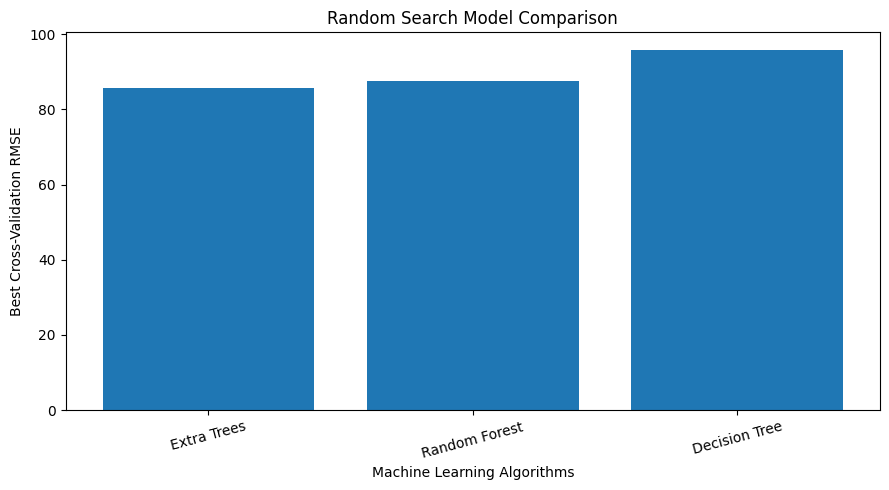

In [15]:
# visualize cross-validation performance of optimized algorithms

plt.figure(figsize=(9, 5))

plt.bar(
    results_df["Model"],
    results_df["Best CV RMSE"]
)

plt.title("Random Search Model Comparison")

plt.xlabel("Machine Learning Algorithms")

plt.ylabel("Best Cross-Validation RMSE")

plt.xticks(rotation=15)

plt.tight_layout()

plt.show()

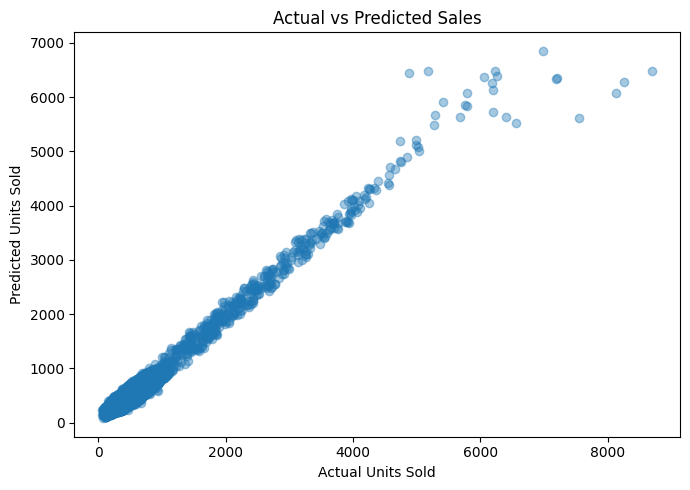

In [16]:
# visualize actual and predicted pharmacy sales

plt.figure(figsize=(7, 5))

plt.scatter(
    y_test,
    y_pred,
    alpha=0.4
)

plt.xlabel("Actual Units Sold")

plt.ylabel("Predicted Units Sold")

plt.title("Actual vs Predicted Sales")

plt.tight_layout()

plt.show()

In [17]:
# display randomized search optimization summary


print("dataset records:", len(df))

print("algorithms optimized:", len(models))

print("random iterations per algorithm: 12")

print("total randomized configurations:", sum(
    len(search.cv_results_["params"])
    for search in random_search_objects.values()
))

print("cross-validation folds:", cv_strategy.n_splits)

print("parallel processing jobs: 2")

print("tuning sample records:", tuning_size)

print("best algorithm:", best_model_name)

print("best parameters:", best_parameters)

print("MAE:", round(mae, 4))

print("RMSE:", round(rmse, 4))

print("R2 score:", round(r2, 4))

print("\nrandomized search optimization completed")

dataset records: 175360
algorithms optimized: 3
random iterations per algorithm: 12
total randomized configurations: 36
cross-validation folds: 3
parallel processing jobs: 2
tuning sample records: 10000
best algorithm: Extra Trees
best parameters: {'model__max_depth': 20, 'model__max_features': 1.0, 'model__min_samples_leaf': 3, 'model__min_samples_split': 13, 'model__n_estimators': 104}
MAE: 64.7676
RMSE: 84.3167
R2 score: 0.939

randomized search optimization completed
